# FaIR: Finite Amplitude Impulse Response Model

This notebook is based on a notebook developed by Chris Smith for [FaIR](https://github.com/OMS-NetZero/FAIR). 

*Note: to run FaIR, you will need to install the python package. Activate your ccia environment and then type
`pip install fair` using the Terminal for Macs or the Anaconda prompt for PCs*

Here are the commands to run using your Mac terminal or the Anaconda Prompt:

1. conda activate ccia

2. pip install fair==1.6.4

"The Finite Amplitude Impulse Response (FaIR) model is a simple emissions-based climate model. It allows the user to input emissions of greenhouse gases and short-lived climate forcers in order to estimate global and annual mean atmospheric greenhouse gas (GHG) concentrations, radiative forcing and temperature anomalies.

The original FaIR model (v1.0) was developed to simulate the earth system response to CO$_2$ emissions, with all non-CO$_2$ forcing implemented as an "external" source. It was developed by Richard Millar, Zebedee Nicholls, Pierre Friedlingstein and Myles Allen. The motivation for developing it and its formulation is documented in a paper published in Atmospheric Chemistry and Physics in 2017 ([doi:10.5194/acp-2016-405](doi:10.5194/acp-2016-405)).

In this lab and the remaining labs, we will use the updated emissions-based FaIR model. The emissions-based model extends FaIR by replacing all sources of non-CO$_2$ forcing with relationships that are based on the source emissions, with the exception of natural forcings (i.e., variations in solar irradiance and volcanic eruptions). It is useful for assessing future policy commitments to anthropogenic emissions (something which we can control) than to radiative forcing (something which is less certain and which we can only partially control).

The emissions-based model was developed by Chris Smith with input from Piers Forster, Leighton Regayre and Giovanni Passerello, in parallel with Nicolas Leach, Richard Millar and Myles Allen." - *description taken from [FaIR](https://github.com/OMS-NetZero/FAIR)*

## What is included in FaIR:

FaIR represents the globally-averaged, annually-averaged climate. Numerically, it consists of simple carbon-cycle model including 5 different carbon reservoirs (geologic (1), deep ocean (2), surface ocean (3), biosphere (4)) within the Earth system and models the exchanges between these and the atmospheric reservoir (5), accournting for their differing residence times, in order to derive atmospheric concentrations of CO$_2$ and radiative forcing from emissions. The model then represents the climate as a two-box system and distributes the radiative forcing between these boxes a surface box and a deep ocean box where heat can be stored.

## What is not included in FaIR:

FaIR is not an Earth System Model like those used for the coupled model intercomparison projects (e.g. CMIP6). It has no horizontal resolution and only two vertical layers, the two boxes. It has no representation of atmospheric, oceanic or cryospheric dynamics. 

*For more information, see the documentation above.*

#### FaIR is a very simple climate model, but it will allow us to explore theoretical concepts using a simple python interface and without taking days to weeks for computations to complete.

In [1]:
# import packages
import fair
import numpy as np
from matplotlib import pyplot as plt
plt.style.use('seaborn-darkgrid')
plt.rcParams['figure.figsize'] = (16, 9)

## Model Validation

One of the key steps in model development is validation. Development is an iterative process. Examination of how a model performs relative to nature and the desire and need to improve model performance drives development. 

To start, we will first examine how well FaIR does at simulating CO$_2$ concentrations and globally and annually averaged temperature anomalies for the historical time period. 

We will use three different data sets to do this:

1. annual mean atmospheric CO$_2$ concentrations from the Mauna Loa Observatory (MLO) (1959-2020)
2. GISTEMP global and annual mean temperature anomalies (1880-2020)
2. HadCRUT5 global and annual mean temperature anomalies (1850-2020)


### Validation of CO$_2$ Concentrations

Remember that FaIR uses *emissions* as the input, rather than concentrations, so checking that FaIR is getting the CO$_2$ concentrations correct, is the first step in the validation process.

We can run FaIR for one of the shared socio-economic pathway (SSP) scenarios, SSP5-8.5, which includes the historical time period (from 1765-2014). To run FaIR, we use the function `fair_scm()`. These SSP scenarios were used for climate model projections in CMIP6. We will talk more about these later in the semester.

By default, volcanic and solar forcing plus natural emissions of methane and nitrous oxide are switched on.

In [16]:
from fair.SSPs import ssp585

# To run FaIR we call fair_scm() and the input is the emissions
# the output include the concentrations, the radiative forcing and the temperature anomalies

C85, F85, T85 = fair.forward.fair_scm(emissions=ssp585.Emissions.emissions)

**Note that `C85` and `F85` are 2-D arrays. The rows represent time and the columns represent each individual forcing, e.g. CO$_2$, CH$_4$, N$_2$O, etc. `T85` is just a 1-D array of temperature anomalies for each year.**

Now, let's just extract the variables for years that overlap with our observational data, the years 1850-2020. Remember that the FaIR integrations start from the year 1765.

In [17]:
# define start and end years for historical period
yr_is = 85 #1850
yr_ie = 256 #2020

# years
year_hist = ssp585.Emissions.year[yr_is:yr_ie]

# CO2 Emissions
CO2E_hist = ssp585.Emissions.co2_fossil[yr_is:yr_ie]

# all GHG concentrations (CO2 is the first element of the second dimension)
C85_hist = C85[yr_is:yr_ie,:]

# Radiative forcing (RF for CO2 is the first element of the second dimension)
F85_hist = F85[yr_is:yr_ie,:]

# Temperature Anomalies
T85_hist = T85[yr_is:yr_ie]

In [18]:
print(year_hist)

[1850 1851 1852 1853 1854 1855 1856 1857 1858 1859 1860 1861 1862 1863
 1864 1865 1866 1867 1868 1869 1870 1871 1872 1873 1874 1875 1876 1877
 1878 1879 1880 1881 1882 1883 1884 1885 1886 1887 1888 1889 1890 1891
 1892 1893 1894 1895 1896 1897 1898 1899 1900 1901 1902 1903 1904 1905
 1906 1907 1908 1909 1910 1911 1912 1913 1914 1915 1916 1917 1918 1919
 1920 1921 1922 1923 1924 1925 1926 1927 1928 1929 1930 1931 1932 1933
 1934 1935 1936 1937 1938 1939 1940 1941 1942 1943 1944 1945 1946 1947
 1948 1949 1950 1951 1952 1953 1954 1955 1956 1957 1958 1959 1960 1961
 1962 1963 1964 1965 1966 1967 1968 1969 1970 1971 1972 1973 1974 1975
 1976 1977 1978 1979 1980 1981 1982 1983 1984 1985 1986 1987 1988 1989
 1990 1991 1992 1993 1994 1995 1996 1997 1998 1999 2000 2001 2002 2003
 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017
 2018 2019 2020]


Next, let's plot the CO$_2$ emissions and concentrations:

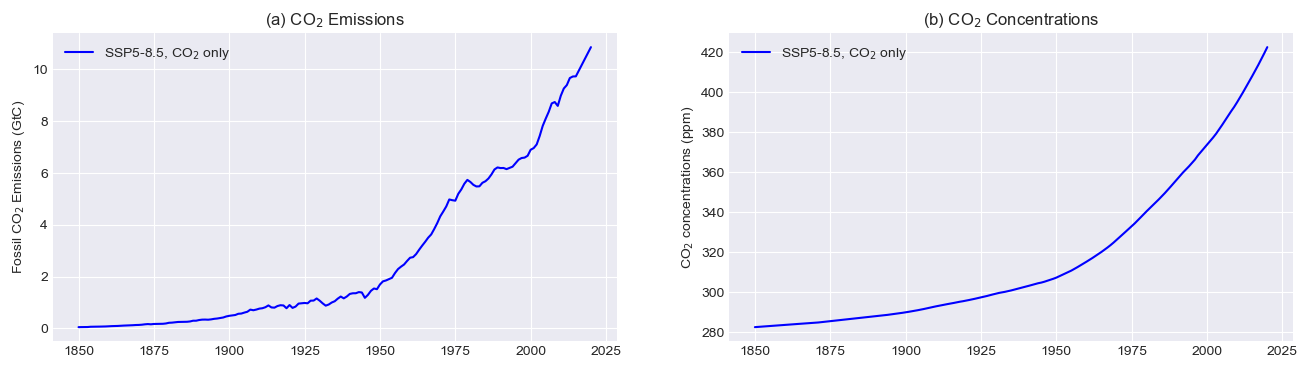

In [19]:
# plot annual CO2 emissions and concentrations
fig = plt.figure(figsize=(16,4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

# plot CO2 emissions
ax1.plot(year_hist, CO2E_hist, color='blue', label='SSP5-8.5, CO$_2$ only')

# plot CO2 concentrations
ax2.plot(year_hist, C85_hist[:,0], color='blue', label='SSP5-8.5, CO$_2$ only')

ax1.set_ylabel('Fossil CO$_2$ Emissions (GtC)')
ax1.set_title('(a) CO$_2$ Emissions')
ax1.legend()
ax2.set_ylabel('CO$_2$ concentrations (ppm)')
ax2.set_title('(b) CO$_2$ Concentrations')
ax2.legend()
#plt.show()
plt.savefig("test.png")

Let's compare the concentrations with the Mauna Loa Observatory (MLO) data. We will need to read in the Mauna Loa data:

In [20]:
# read in MLO co2 concentrations
mlo_co2 = np.genfromtxt('mlo_co2.csv',delimiter=',')

In [21]:
mlo_co2

array([[1959.  ,  315.98],
       [1960.  ,  316.91],
       [1961.  ,  317.64],
       [1962.  ,  318.45],
       [1963.  ,  318.99],
       [1964.  ,  319.62],
       [1965.  ,  320.04],
       [1966.  ,  321.37],
       [1967.  ,  322.18],
       [1968.  ,  323.05],
       [1969.  ,  324.62],
       [1970.  ,  325.68],
       [1971.  ,  326.32],
       [1972.  ,  327.46],
       [1973.  ,  329.68],
       [1974.  ,  330.19],
       [1975.  ,  331.12],
       [1976.  ,  332.03],
       [1977.  ,  333.84],
       [1978.  ,  335.41],
       [1979.  ,  336.84],
       [1980.  ,  338.76],
       [1981.  ,  340.12],
       [1982.  ,  341.48],
       [1983.  ,  343.15],
       [1984.  ,  344.85],
       [1985.  ,  346.35],
       [1986.  ,  347.61],
       [1987.  ,  349.31],
       [1988.  ,  351.69],
       [1989.  ,  353.2 ],
       [1990.  ,  354.45],
       [1991.  ,  355.7 ],
       [1992.  ,  356.54],
       [1993.  ,  357.21],
       [1994.  ,  358.96],
       [1995.  ,  360.97],
 

Check the shape of the MLO data. What do we have? We should have two columns of data, one showing the year and one showing the concentrations.

Let's add these data to our plot:

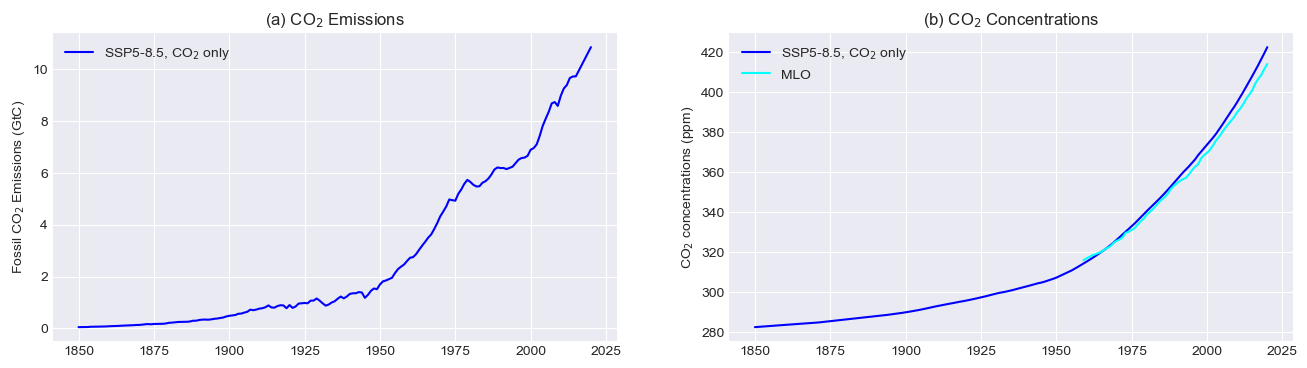

In [22]:
# plot annual CO2 emissions and concentrations
fig = plt.figure(figsize=(16,4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

# plot CO2 emissions
ax1.plot(year_hist, CO2E_hist, color='blue', label='SSP5-8.5, CO$_2$ only')

# plot CO2 concentrations
ax2.plot(year_hist, C85_hist[:, 0], color='blue', label='SSP5-8.5, CO$_2$ only')
# add MLO data to ax2

# complete the plotting line...
ax2.plot(mlo_co2[:,0],mlo_co2[:,1],color='cyan', label='MLO')

ax1.set_ylabel('Fossil CO$_2$ Emissions (GtC)')
ax1.set_title('(a) CO$_2$ Emissions')
ax1.legend()
ax2.set_ylabel('CO$_2$ concentrations (ppm)')
ax2.set_title('(b) CO$_2$ Concentrations')
ax2.legend()
plt.show()

It looks like there is a bit of a difference between the model and the observations - the observations seem to be slighty higher than the model for most of the overlapping time period. To see how large the difference is, let's compute the model ***bias***.

$$
\overline{[CO_2]_{Bias}} = \overline{[CO_2]_{FaIR}} - \overline{[CO_2]_{obs}}
$$

where $[...]$ indicates concentration and $\overline{(...)}$ indicates a long-term or *climatological* average. 

Let's take the long-term average over a typical representative time period, 1961-1990. Note that beyond the year 2014, the historical time period ends and the SSP scenarios begin, so we might not expect perfect agreement beyond 2014.

In [23]:
# compute the bias for 1961-1990
co2_bias = np.mean(C85_hist[111:141,0],axis=0) - np.mean(mlo_co2[2:32,1],axis=0)
print("The FaIR [CO$_2$] bias is ", np.round(co2_bias,2), " ppm.")

The FaIR [CO$_2$] bias is  1.04  ppm.


In other words, FaIR is *underestimating* the [CO$_2$] concentration. This might mean that either the ocean or land carbon sinks (or both) are sequestering too much CO$_2$ relative to nature, or that the emissions of CO$_2$ that drive the model are underestimated. 

If we want to know what is causing the bias, this would require more investigation. For now, we will just quantify the bias and be relatively satisfied that the model and the observations are in pretty good agreement.

We could do the same bias calculation for the other GHGs, but for this lab, we will just stick with CO$_2$.

### Validation of Temperature Anomalies

Now, we are going to see how well FaIR represents the global and annual surface temperature anomalies. 

Let's start by adding the historical radiative forcing and temperature anomalies from FaIR to our plot:

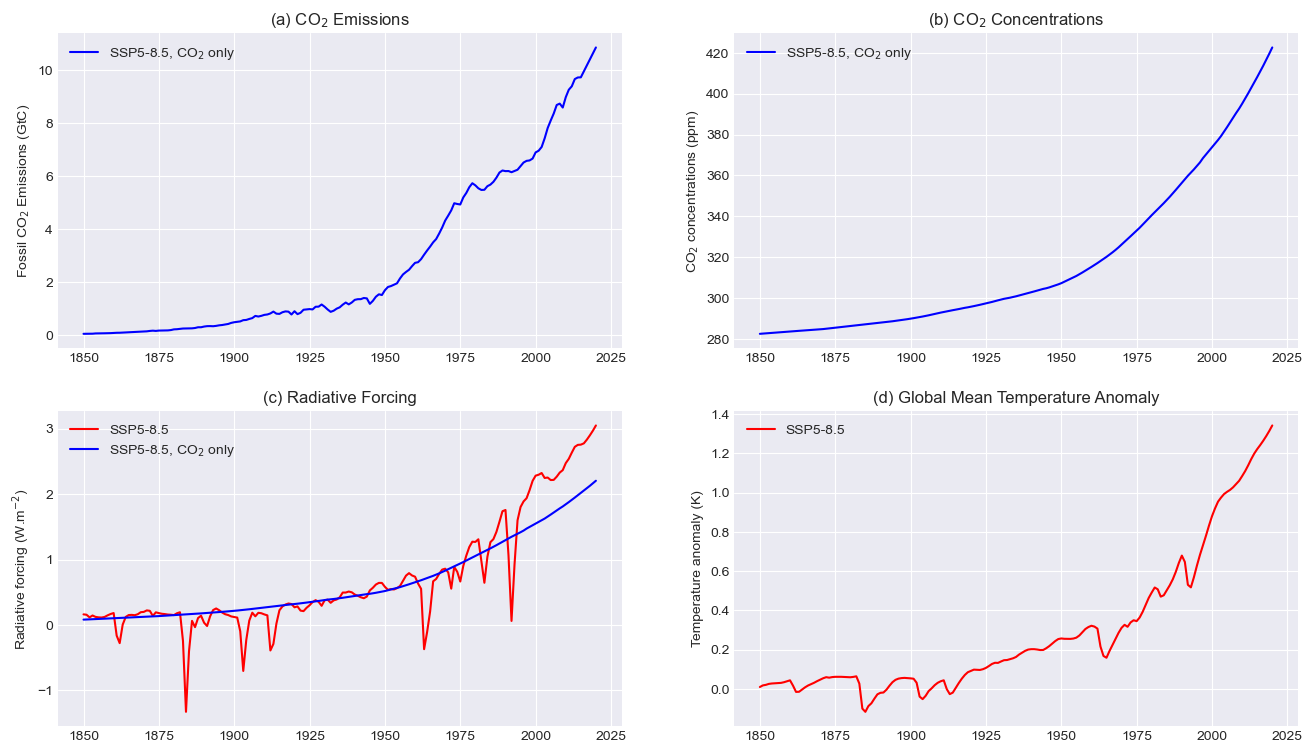

In [24]:
# plot everything (E, C, F, T)

fig = plt.figure()
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax3 = fig.add_subplot(223)
ax4 = fig.add_subplot(224)

# plot CO2 emissions
ax1.plot(year_hist, CO2E_hist, color='blue', label='SSP5-8.5, CO$_2$ only')

# plot CO2 concentrations
ax2.plot(year_hist, C85_hist[:, 0], color='blue', label='SSP5-8.5, CO$_2$ only')
# add MLO data to ax2
#ax2.plot(mlo_co2[:,0],mlo_co2[:,1],color='cyan', label='MLO')

# plot total radiative forcing
ax3.plot(year_hist, np.sum(F85_hist, axis=1), color='r', label='SSP5-8.5')
ax3.plot(year_hist, F85_hist[:,0], color='blue',label="SSP5-8.5, CO$_2$ only")

# plot temperature anomalies
ax4.plot(year_hist, T85_hist, color='r', label='SSP5-8.5')

ax1.set_ylabel('Fossil CO$_2$ Emissions (GtC)')
ax1.set_title('(a) CO$_2$ Emissions')
ax1.legend()
ax2.set_ylabel('CO$_2$ concentrations (ppm)')
ax2.set_title('(b) CO$_2$ Concentrations')
ax2.legend()
ax3.set_ylabel('Radiative forcing (W.m$^{-2}$)')
ax3.set_title('(c) Radiative Forcing')
ax3.legend()
ax4.set_ylabel('Temperature anomaly (K)')
ax4.set_title('(d) Global Mean Temperature Anomaly')
ax4.legend()
plt.show()

Great! The RF and temperature anomalies look reasonable, but let's quantify this.

We are going to compute the surface temperature bias, just as we did for the [CO$_2$] bias.

Let's read in our two surface temperature data sets:

In [25]:
# read surface temperature data

T_gis = np.genfromtxt('GLB.Ts+dSST.csv',delimiter=',') #anomalies relative to 1951-1980
T_had = np.genfromtxt('HadCRUT.5.0.1.0.analysis.summary_series.global.annual.csv',delimiter=',') #anomalies relative to 1961-1990

Check the shape of this data sets. What does each column represent? You may want to print out each column.

Before we add these time series to our plot to compare with FaIR, let's plot them separately first.

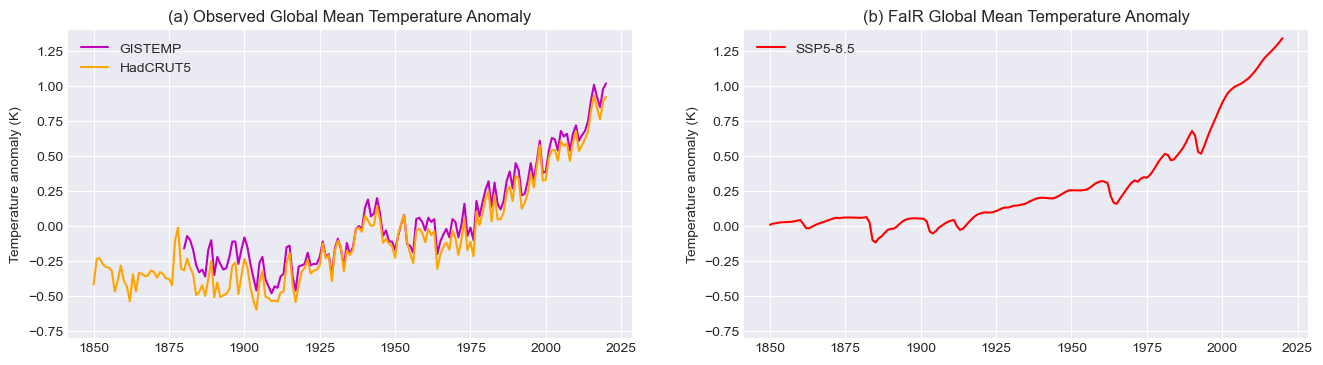

In [26]:
# plot annual CO2 emissions and concentrations
fig = plt.figure(figsize=(16,4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

# plot observational temperature anomalies
ax1.plot(T_gis[:,0],T_gis[:,1],color='m',label="GISTEMP")
ax1.plot(T_had[:,0],T_had[:,1],color='orange',label="HadCRUT5")

# plot FaIR temperature anomalies
ax2.plot(year_hist, T85_hist, color='r', label='SSP5-8.5')

ax1.set_ylabel('Temperature anomaly (K)')
ax1.set_title('(a) Observed Global Mean Temperature Anomaly')
ax1.set_ylim(-0.8,1.4)
ax1.legend(loc="upper left")

ax2.set_ylabel('Temperature anomaly (K)')
ax2.set_title('(b) FaIR Global Mean Temperature Anomaly')
ax2.set_ylim(-0.8,1.4)
ax2.legend()
plt.show()

A couple of things to notice:
1. GISTEMP and HadCRUT5 are different from one another. GISTEMP is systematically warmer, particularly in the early part of the record. 
2. The y-axis range is quite different for the observations versus FaIR. This has to do with how the anomalies are computed, i.e. with respect to what baseline (Note some of the difference between GISTEMP and HadCRUT5 also has to do with the different choice of baseline).
    - FaIR considers the pre-industrial era as the baseline while GISTEMP and HadCRUT5 use 1951-1980 and 1961-1990, respectively.
    
So, what should we do?

Adjust our temperature anomalies by computing a consistent baseline for each product, 1850-1900, as in the FaIR model.

Because GISTEMP doesn't go back to 1850, we will use HadCRUT5 to compute the baseline.

In [27]:
# adjust baseline. Let's use a consistent baseline for each observational data product, 1880-1899
T_gis_adj = T_gis[:,1] - np.mean(T_had[0:50,1])
T_had_adj = T_had[:,1] - np.mean(T_had[0:50,1])

Now, let's replot the data all on the same axis:

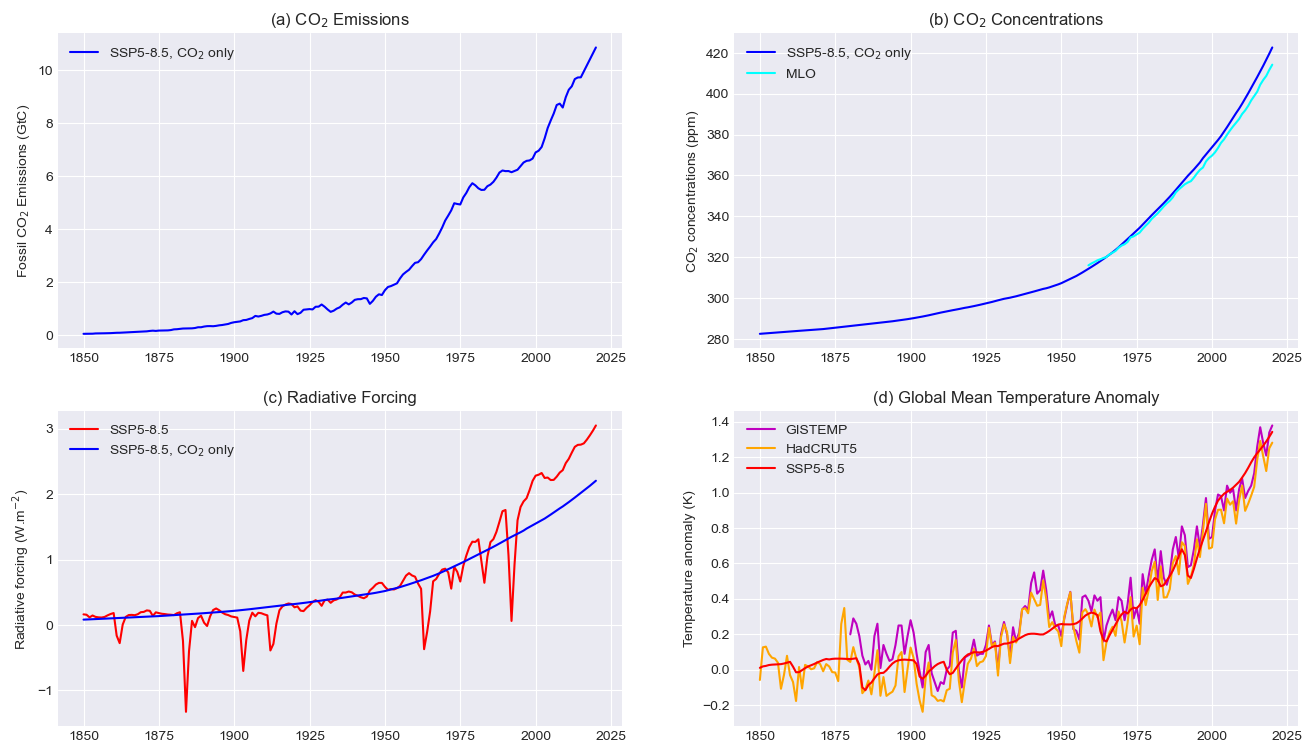

In [28]:
# plot annual CO2 emissions and concentrations
fig = plt.figure()
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax3 = fig.add_subplot(223)
ax4 = fig.add_subplot(224)

# plot CO2 emissions
ax1.plot(year_hist, CO2E_hist, color='blue', label='SSP5-8.5, CO$_2$ only')

# plot CO2 concentrations
ax2.plot(year_hist, C85_hist[:, 0], color='blue', label='SSP5-8.5, CO$_2$ only')
# add MLO data to ax2
ax2.plot(mlo_co2[:,0],mlo_co2[:,1],color='cyan', label='MLO')

# plot total radiative forcing
ax3.plot(year_hist, np.sum(F85_hist, axis=1), color='r', label='SSP5-8.5')
ax3.plot(year_hist, F85_hist[:,0], color='blue',label="SSP5-8.5, CO$_2$ only")

# plot observational temperature anomalies
ax4.plot(T_gis[:,0],T_gis_adj,color='m',label="GISTEMP")
ax4.plot(T_had[:,0],T_had_adj,color='orange',label="HadCRUT5")

# plot FaIR temperature anomalies
ax4.plot(year_hist, T85_hist, color='r', label='SSP5-8.5')

ax1.set_ylabel('Fossil CO$_2$ Emissions (GtC)')
ax1.set_title('(a) CO$_2$ Emissions')
ax1.legend()
ax2.set_ylabel('CO$_2$ concentrations (ppm)')
ax2.set_title('(b) CO$_2$ Concentrations')
ax2.legend()
ax3.set_ylabel('Radiative forcing (W.m$^{-2}$)')
ax3.set_title('(c) Radiative Forcing')
ax3.legend()
ax4.set_ylabel('Temperature anomaly (K)')
ax4.set_title('(d) Global Mean Temperature Anomaly')
ax4.legend()
plt.show()

Great! Now, we see a bit better agreement. Let's compute the model bias for the 1961-1990 time period again. Let's just compute the bias relative to the HadCRUT5 data set for now. Remember to compute the bias relative to the *adjusted* HadCRUT5 data set.

In [29]:
# compute the temperature bias
T_bias = np.mean(T85_hist[111:141]) - np.mean(T_had_adj[111:141],axis=0)
print("The FaIR temperature bias is ", np.round(T_bias,2), " K")

The FaIR temperature bias is  0.02  K


### Validation of Equilibrium Climate Sensitivity

The final validation test that we will conduct with FaIR is to test the **equilibrium climate sensitivity** (ECS) of FaIR. Recall that the ECS is the equilibrium temperature response to a doubling of CO$_2$ concentrations. 

To perform this test, we will run FaIR in the *concentration-driven* mode. It is possible to drive FaIR with concentrations rather than emissions. To do this, we will set the `emissions_driven` keyword to `False` and specify the concentrations with `C`. The function still returns the `C, F, T`.

(-0.5, 3.0)

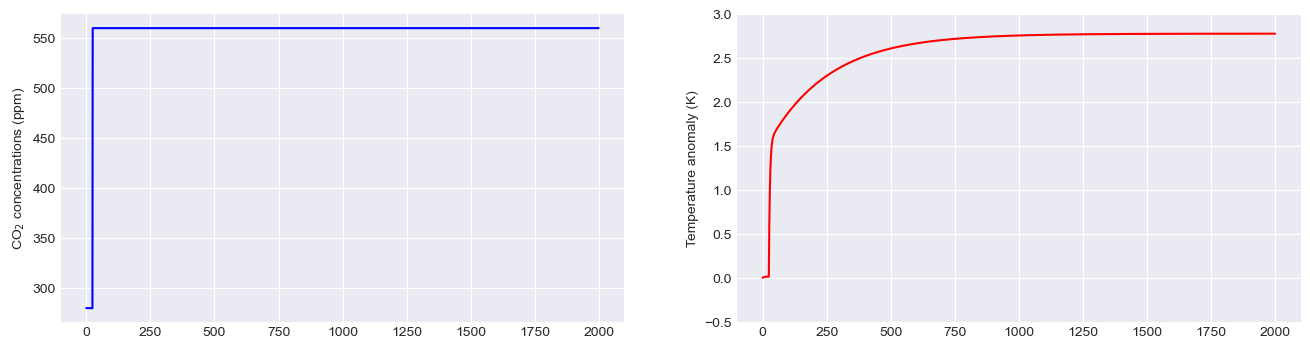

In [30]:
# create an array of CO2 concentrations

# initialize with a pre-industrial concentration of 280 ppm
C_conc = 280*np.ones(2000)

# after 25 years, double it for the remainder of the run
C_conc[25:] = 560.0
    
# run FaIR in concentration-driven mode    
C,F,T = fair.forward.fair_scm(emissions_driven=False,C = C_conc,useMultigas=False)

# plot 
fig = plt.figure(figsize=(16,4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

# plot the CO2 concentrations
ax1.plot(range(0, C_conc.size), C, color='blue')
ax1.set_ylabel('CO$_2$ concentrations (ppm)')

# plot the temperature anomalies

ax2.plot(range(0, C_conc.size), T, color='red')
ax2.set_ylabel('Temperature anomaly (K)')
ax2.set_ylim(-0.5,3)

Has FaIR reached equilibrium? Extend the length of the concentration array to integrate FaIR for more years. 
- Roughly when does FaIR reach equilibrium? 
- What is the resulting ECS for FaIR? How does this compare to the best estimate reported in the IPCC AR6?

We have now examined whether or not FaIR provides a reasonable representation of the climate system response to emissions. In the next lab, we will use FaIR to do a more direct quantification of the human influence on surface temperature change.

In [31]:
for i in range(len(T)-1):
    if np.abs(T[i]-T[i+1])<0.0001:
        print(T[i],i)

0.01652988833284618 17
0.016619744634087677 18
0.016700541075630283 19
0.01677419516181361 20
0.016842209561258623 21
0.016905761891463617 22
0.016965775070791327 23
2.7545863293433523 967
2.754685928435369 968
2.7547851116653934 969
2.7548838807697997 970
2.7549822374777104 971
2.75508018351103 972
2.7551777205844714 973
2.7552748504055895 974
2.7553715746748093 975
2.755467895085455 976
2.7555638133237816 977
2.755659331069003 978
2.755754449993322 979
2.7558491717619593 980
2.755943498033182 981
2.756037430458334 982
2.7561309706818644 983
2.756224120341356 984
2.7563168810675536 985
2.7564092544843932 986
2.7565012422090316 987
2.7565928458518707 988
2.7566840670165913 989
2.756774907300177 990
2.7568653682929423 991
2.7569554515785635 992
2.7570451587341034 993
2.7571344913300404 994
2.7572234509302946 995
2.757312039092258 996
2.757400257366819 997
2.7574881072983892 998
2.757575590424934 999
2.757662708277995 1000
2.757749462382722 1001
2.757835854257894 1002
2.7579218854159486 